# SEMMA: Mall Customer Segmentation

Sample → Explore → Modify → Model → Assess. This is a Python/Colab implementation of the SAS-inspired SEMMA workflow.

In [1]:
import os, numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
DATA_PATH='data/Mall_Customers.csv'
assert os.path.exists(DATA_PATH), 'Download the Kaggle CSV; see ../data/README.md'
df=pd.read_csv(DATA_PATH)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Sample and Explore

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

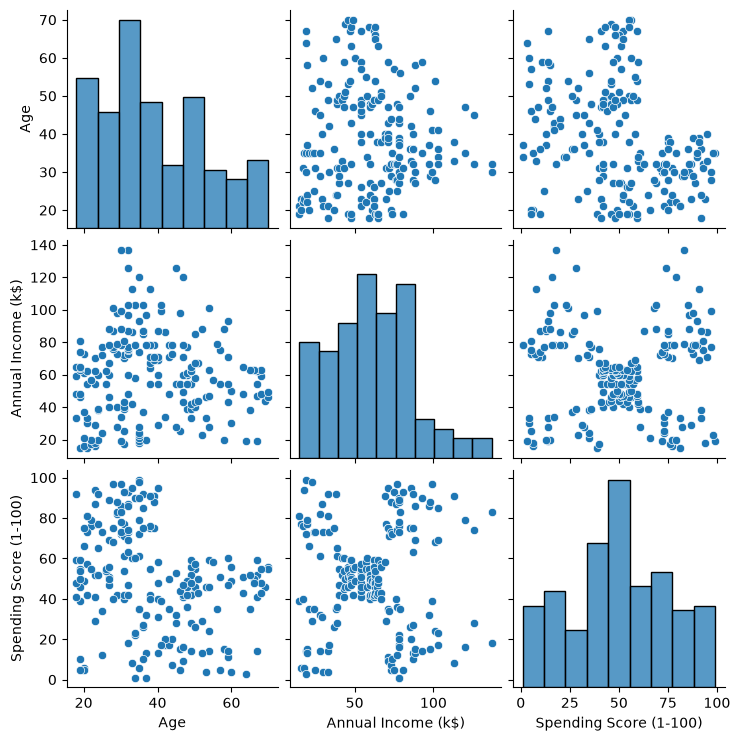

In [2]:
print(df.info()); display(df.describe(include='all'))
display(df.isna().sum())
sns.pairplot(df[['Age','Annual Income (k$)','Spending Score (1-100)']]); plt.show()

## Modify

Annual income and spending score are used as segmentation variables. Standardization prevents income's scale from dominating Euclidean distance.

In [3]:
features=['Annual Income (k$)','Spending Score (1-100)']
X=df[features].dropna()
Z=StandardScaler().fit_transform(X)
scores=[]
for k in range(2,9):
    km=KMeans(n_clusters=k,n_init=20,random_state=42).fit(Z)
    scores.append({'k':k,'inertia':km.inertia_,'silhouette':silhouette_score(Z,km.labels_)})
scores=pd.DataFrame(scores); display(scores)

,k,inertia,silhouette
0,2,269.691012,0.321271
1,3,157.704008,0.466585
2,4,108.921317,0.493907
3,5,65.568408,0.554657
4,6,55.057348,0.539880
5,7,44.864756,0.528149
6,8,37.148117,0.456721


## Model and Assess

Annual Income (k$)                   Spending Score (1-100)  \
                     count       mean median                  count   
cluster                                                               
0                       81  55.296296   54.0                     81   
1                       39  86.538462   79.0                     39   
2                       22  25.727273   24.5                     22   
3                       35  88.200000   85.0                     35   
4                       23  26.304348   25.0                     23   

                           
              mean median  
cluster                    
0        49.518519   50.0  
1        82.128205   83.0  
2        79.363636   77.0  
3        17.114286   16.0  
4        20.913043   17.0

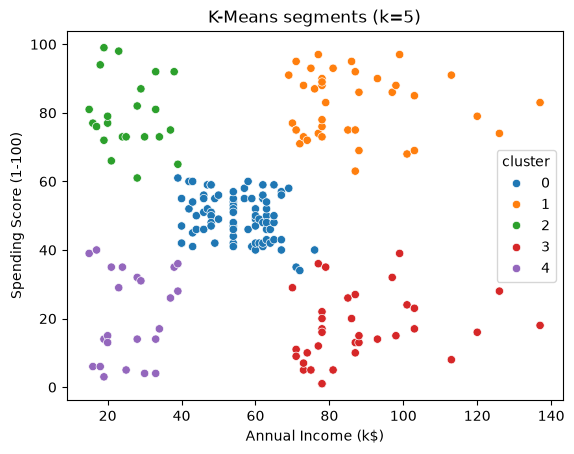

In [4]:
best_k=int(scores.loc[scores.silhouette.idxmax(),'k'])
km=KMeans(n_clusters=best_k,n_init=20,random_state=42).fit(Z)
seg=X.copy(); seg['cluster']=km.labels_
display(seg.groupby('cluster').agg(['count','mean','median']))
sns.scatterplot(data=seg,x=features[0],y=features[1],hue='cluster',palette='tab10'); plt.title(f'K-Means segments (k={best_k})'); plt.show()

Recommendations are hypotheses: profile-based campaigns should be tested with randomized outcomes. Refit across multiple seeds and monitor whether segment profiles remain stable before operational use.